# 01 · Data audit — BraTS 2020 (training set)

Generated from `python -m src.preprocess` and `python -m src.audit`. This notebook only *reads* those outputs, so it runs in seconds.

In [1]:
import os, json, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, '.')
import pandas as pd
from IPython.display import Image, Markdown, display
pat = pd.read_csv('data/processed/patients.csv')
sl = pd.read_csv('data/processed/slices.csv')
display(Markdown(open('reports/audit/summary.md').read()))

# Data audit — BraTS 2020 training set

- Patients found: **369**, usable: **369**, skipped: none
- File issues: BraTS20_Training_355: misnamed seg file 'W39_1998.09.19_Segm.nii' (used it)
- Shapes: {'240x240x155': 369}; voxel size: {'1x1x1': 369}
- Label sets: {'0,1,2,4': 340, '0,1,2': 27, '0,2,4': 1, '0,1,4': 1}
- Image dtypes: {'int16': 335, 'float32': 34}; seg dtypes: {'uint8': 255, 'int16': 71, 'uint16': 43}
- Tumor voxels outside the brain mask: 1248
- Largest brain extent (px): [157, 193]; crop sides used: {192: 358, 195: 4, 193: 3, 194: 1, 197: 1, 201: 1, 196: 1}
- No patient in two splits: **True**

## Splits

| split | patients | HGG | LGG | cached slices | with tumor | tumor-free |
|---|---|---|---|---|---|---|
| train | 258 | 205 | 53 | 34,528 | 16,995 | 17,533 |
| val | 55 | 44 | 11 | 7,481 | 3,734 | 3,747 |
| test | 56 | 44 | 12 | 7,472 | 3,693 | 3,779 |

Training slices per epoch (all tumor + 2,630 sampled tumor-free): **19,625**

## Tumor volume (mL)

| region | mean | median | min | max | patients with 0 |
|---|---|---|---|---|---|
| WT | 99.5 | 90.7 | 7.28 | 361.8 | 0 |
| TC | 41.8 | 33.8 | 0.56 | 190.2 | 0 |
| ET | 19.7 | 15.1 | 0.0 | 111.2 | 27 |

## Resampling ceiling (GT → 160 px → native, Dice)

| region | mean | min |
|---|---|---|
| WT | 0.9853 | 0.9534 |
| TC | 0.9843 | 0.9256 |
| ET | 0.9565 | 0.2222 |

## Disk

- Raw zip: 4.2G
- Processed cache: 11G


## Files with issues

In [2]:
pat.loc[pat.issues.notna(), ['pid', 'grade', 'split', 'status', 'issues']]

,pid,grade,split,status,issues
354,BraTS20_Training_355,HGG,test,ok,misnamed seg file 'W39_1998.09.19_Segm.nii' (u...


## What the data looks like
Cropped, normalized 160×160 slices for a large HGG, a typical LGG, and the smallest tumor.

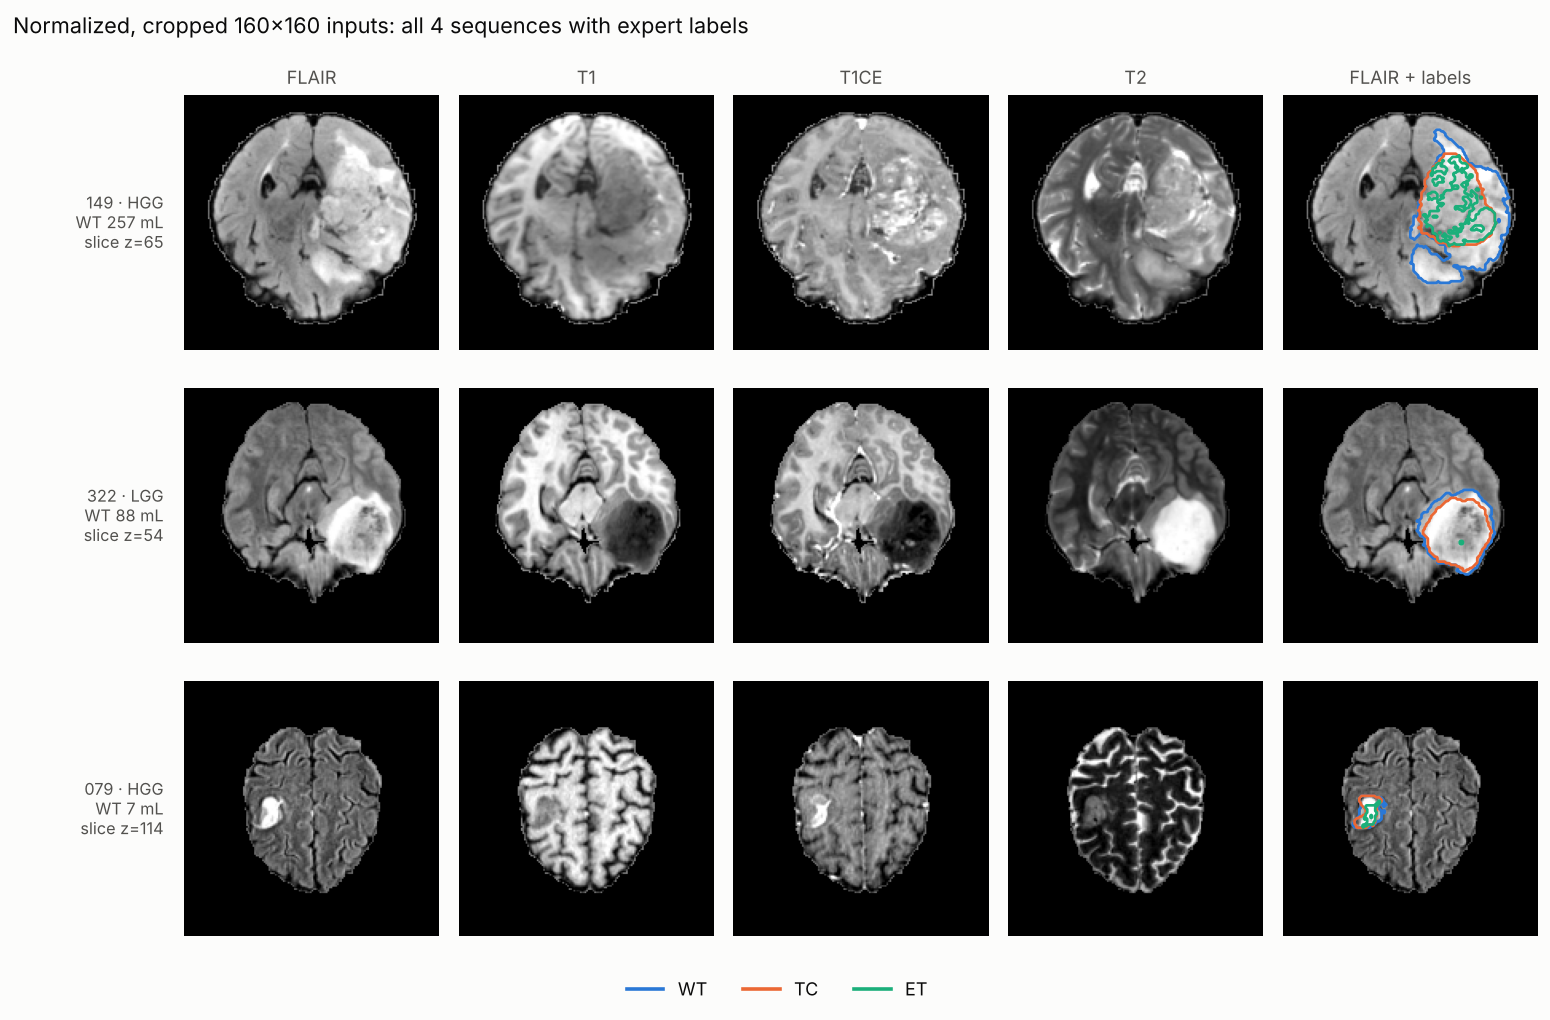

In [3]:
Image('reports/audit/samples.png')

## Slices with vs without tumor

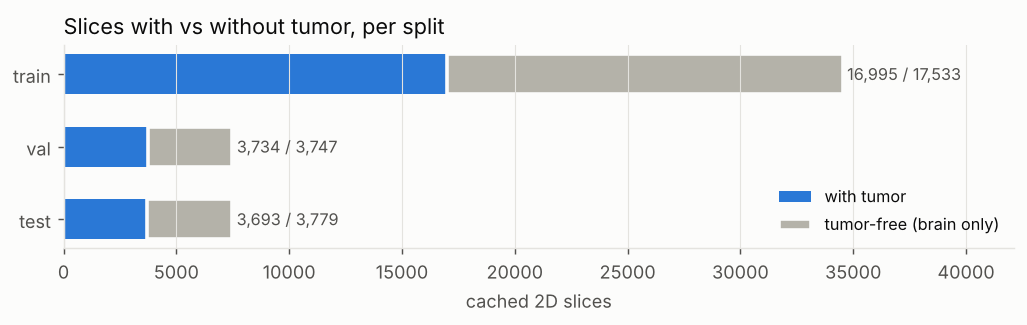

In [4]:
Image('reports/audit/slices_per_split.png')

## Tumor volume per region

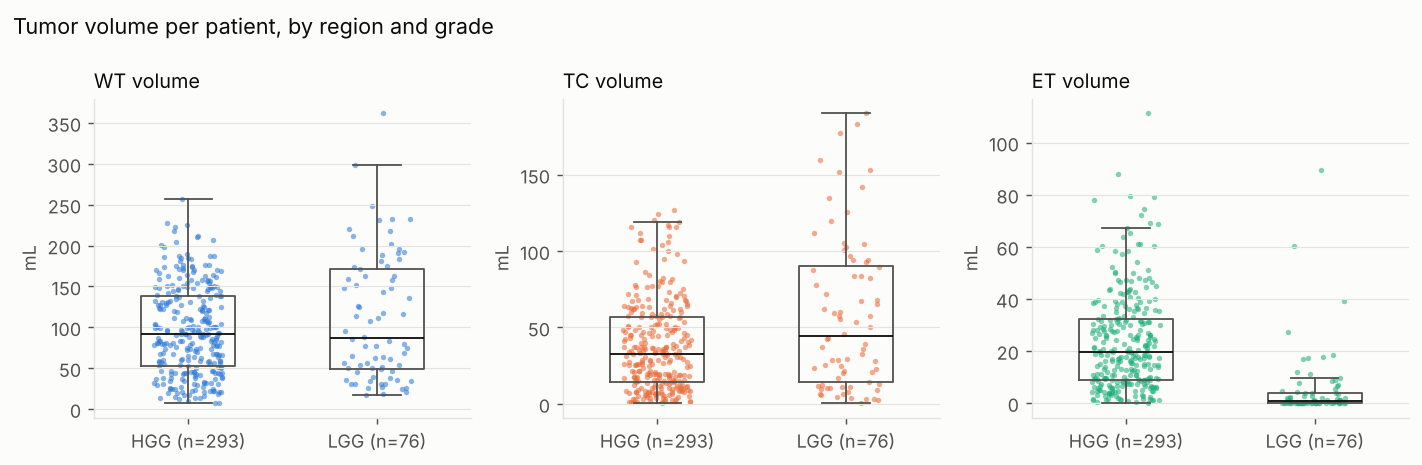

grade              HGG    LGG
vol_WT_ml count  293.0   76.0
          mean    96.4  111.5
          std     53.8   76.7
          min      7.3   17.1
          25%     52.5   48.4
          50%     91.1   86.3
          75%    138.1  171.6
          max    256.9  361.8
vol_TC_ml count  293.0   76.0
          mean    37.7   57.8
          std     29.3   49.7
          min      0.6    0.8
          25%     14.3   14.1
          50%     32.5   44.6
          75%     56.6   90.2
          max    126.7  190.2
vol_ET_ml count  293.0   76.0
          mean    23.4    5.5
          std     18.5   13.5
          min      0.1    0.0
          25%      9.0    0.0
          50%     19.5    0.8
          75%     32.4    3.9
          max    111.2   89.5

In [5]:
display(Image('reports/audit/tumor_volumes.png'))
pat.groupby('grade')[['vol_WT_ml', 'vol_TC_ml', 'vol_ET_ml']].describe().T.round(1)

## Intensity normalization check
After per-sequence z-scoring on brain voxels, every sequence should be centred near 0 with unit spread.

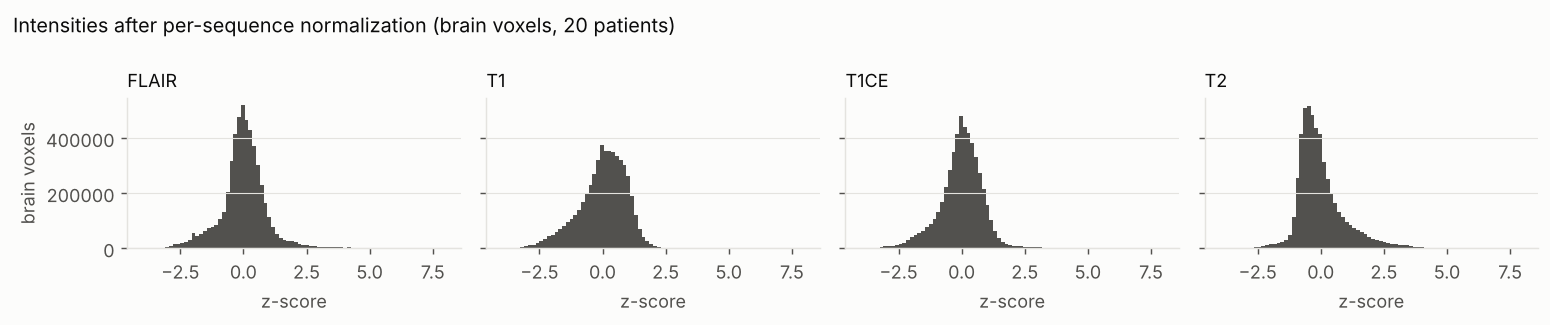

In [6]:
Image('reports/audit/intensity.png')

## Augmentation

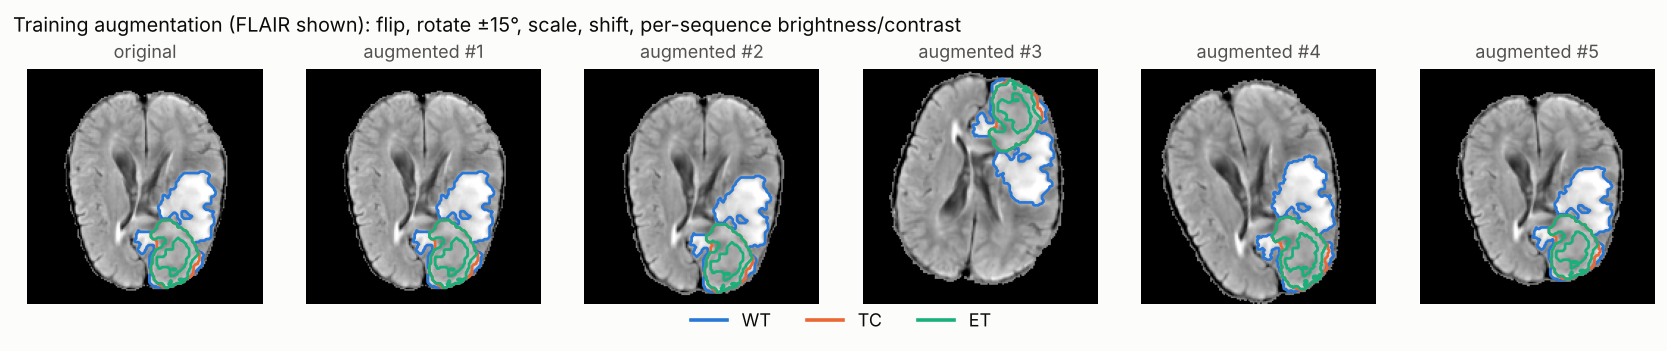

In [7]:
Image('reports/audit/augmentation.png')

## Resampling ceiling
Dice of the ground truth after resizing to 160 px and back to native resolution — the best any model trained at 160 px could reach.

In [8]:
pat[['ceiling_dice_WT', 'ceiling_dice_TC', 'ceiling_dice_ET']].describe().round(4)

,ceiling_dice_WT,ceiling_dice_TC,ceiling_dice_ET
count,369.0000,369.0000,369.0000
mean,0.9853,0.9843,0.9565
std,0.0067,0.0088,0.0516
min,0.9534,0.9256,0.2222
25%,0.9830,0.9813,0.9485
50%,0.9872,0.9870,0.9642
75%,0.9898,0.9900,0.9765
max,0.9938,0.9945,1.0000
